## Replay Results: 21 Months of Simulated Production

The pipeline was replayed month by month from **January 2025 to September 2026**. Each month it:
1. scored the current champion on the new month (monitoring),
2. scored the baseline ("same shift last week"),
3. checked for data drift (each borough vs its previous 90 days, 10% threshold),
4. trained a challenger on all data before that month,
5. promoted the challenger only if its MAE was lower.

The chart compares the champion's monthly error with the baseline's.

In [1]:
import os
os.chdir("/workspaces/nyc-ems-demand-pipeline")

import pandas as pd
import matplotlib.pyplot as plt

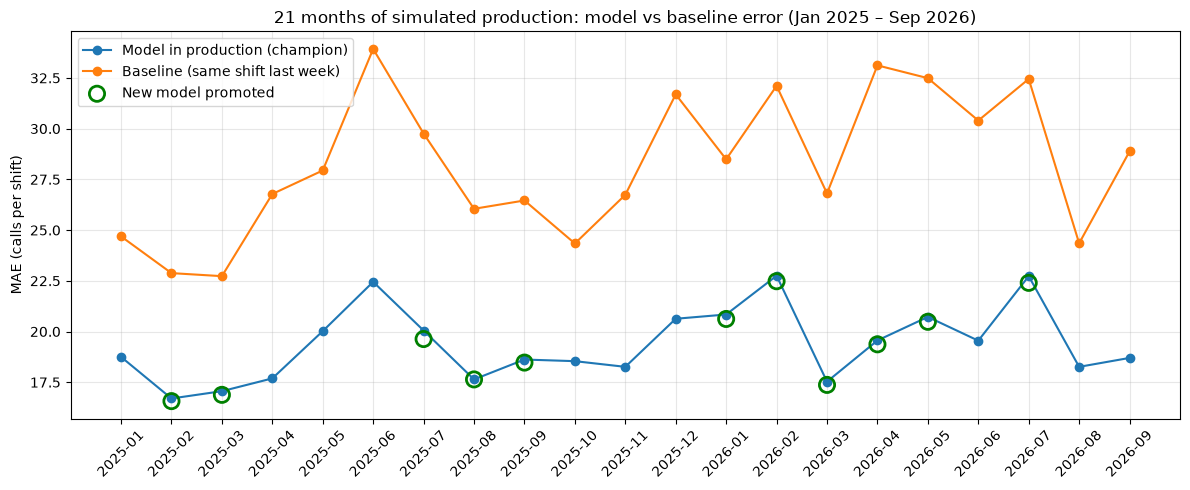

Promoted 11 of 21 months
Average champion MAE: 19.38
Average baseline MAE: 28.24


In [3]:
summary = pd.read_csv("models/replay_summary.csv")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(summary["month"], summary["champion_mae"], marker="o", label="Model in production (champion)")
ax.plot(summary["month"], summary["baseline_mae"], marker="o", label="Baseline (same shift last week)")
promoted = summary[summary["promoted"]]
ax.scatter(promoted["month"], promoted["challenger_mae"], s=120, facecolors="none",
           edgecolors="green", linewidths=2, label="New model promoted", zorder=3)
ax.set_title("21 months of simulated production: model vs baseline error (Jan 2025 – Sep 2026)")
ax.set_ylabel("MAE (calls per shift)")
plt.xticks(rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Promoted {summary['promoted'].sum()} of {len(summary)} months")
print(f"Average champion MAE: {summary['champion_mae'].mean():.2f}")
print(f"Average baseline MAE: {summary['baseline_mae'].mean():.2f}")

In [5]:
plt.savefig("notebooks/replay_results.png")

<Figure size 640x480 with 0 Axes>